# Sensibilidad de CVA con factores de mercado

## Resumen
Spreads Baa y Treasury de FRED; exposición y dependencia son supuestos, no WWR observado.

## Contexto y método
El diferencial Baa incluye factores ajenos al default. La exposición, LGD, hazard y relación de estrés se imponen; no hay contraparte, acuerdos de neteo ni validación de CVA o WWR.

## Datos y preparación
Ejecutar desde la raíz del repositorio o la carpeta del proyecto. Requiere Python, pandas, matplotlib y Jupyter.

Fuentes: [FRED BAA10Y](https://fred.stlouisfed.org/series/BAA10Y) y [FRED DGS10](https://fred.stlouisfed.org/series/DGS10). La descarga requiere `curl` y acceso a internet; LGD 60 %, EPE USD 1 millón y horizonte cinco años.

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, hashlib
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').is_dir())
plt.rcParams.update({'figure.figsize':(9,4), 'axes.grid':True})

In [2]:
import tempfile, subprocess, sys
from urllib.request import urlretrieve
with tempfile.TemporaryDirectory() as d:
    files=[]
    for series in ['BAA10Y','DGS10']:
        p=Path(d)/(series+'.csv'); subprocess.run(['curl','-fsSL','--max-time','60','https://fred.stlouisfed.org/graph/fredgraph.csv?id='+series,'-o',str(p)],check=True); print(series, 'SHA-256:', hashlib.sha256(p.read_bytes()).hexdigest()); files.append(str(p))
    script=root/'03-financial-risk/07-financial-and-construction-risk-lab/01-corporate-financial-risk/05-counterparty-cva-and-wrong-way-risk/public_proxy.py'
    result=subprocess.run([sys.executable,str(script),*files],capture_output=True,text=True,check=True)
    from io import StringIO
    df=pd.read_csv(StringIO(result.stdout),parse_dates=['date'])
print('Observaciones:',len(df),'| Periodo:',df.date.min().date(),'a',df.date.max().date())
df.tail(3)

BAA10Y SHA-256: 0b34e9c06d0aa7c5ffa66a8d067f978719eb9fb1558af8b711503403e08c4246
DGS10 SHA-256: 0a19145416475025a3db81f1d24cddde626211cc098ccba2c22c4baf426c5bb4


Observaciones: 1248 | Periodo: 2020-01-02 a 2024-12-31


,date,baa_spread_pct,treasury_10y_pct,hazard_proxy,cva_fixed_epe_usd,cva_stress_epe_usd
1245,2024-12-27,1.40,4.62,0.023333,57766.81,57766.81
1246,2024-12-30,1.43,4.55,0.023833,59053.27,59053.27
1247,2024-12-31,1.42,4.58,0.023667,58613.04,58613.04


## Resultados

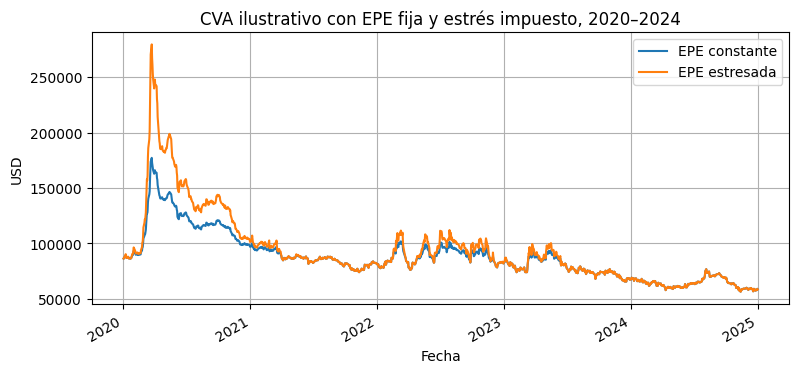

Medianas USD: {'cva_fixed_epe_usd': 85360.0, 'cva_stress_epe_usd': 85900.0}


In [3]:
ax=df.plot(x='date',y=['cva_fixed_epe_usd','cva_stress_epe_usd'],title='CVA ilustrativo con EPE fija y estrés impuesto, 2020–2024'); ax.set(xlabel='Fecha',ylabel='USD'); ax.legend(['EPE constante','EPE estresada']); plt.show()
print('Medianas USD:',df[['cva_fixed_epe_usd','cva_stress_epe_usd']].median().round(0).to_dict())

### Comprobación de supuestos y sensibilidad
La exposición estresada se define para no ser inferior a la base. La diferencia entre curvas refleja la regla impuesta, no una estimación de dependencia entre contraparte y mercado.

In [4]:
assert df.date.is_unique and df.date.is_monotonic_increasing
assert (df[['baa_spread_pct','hazard_proxy','cva_fixed_epe_usd']] > 0).all().all()
assert (df.cva_stress_epe_usd >= df.cva_fixed_epe_usd).all()
df['incremento_usd']=df.cva_stress_epe_usd-df.cva_fixed_epe_usd
print('Días con estrés activo:',int((df.incremento_usd>0).sum()),'de',len(df))
print('Incremento hipotético máximo (USD):',round(df.incremento_usd.max(),2))
df.loc[df.incremento_usd.idxmax(),['date','baa_spread_pct','cva_fixed_epe_usd','cva_stress_epe_usd','incremento_usd']]

Días con estrés activo: 564 de 1248
Incremento hipotético máximo (USD): 102314.02


date                  2020-03-23 00:00:00
baa_spread_pct                       4.31
cva_fixed_epe_usd               177167.15
cva_stress_epe_usd              279481.17
incremento_usd                  102314.02
Name: 55, dtype: object

## Variantes: fracción crediticia del spread y horizonte
El proxy anterior atribuye el 100 % del diferencial Baa al incumplimiento; aquí contrastamos 50 % y 100 %, con horizonte de tres y cinco años y EPE constante. Bajo intensidad constante, la probabilidad acumulada de default supuesta es $1-e^{-\lambda T}$ y $\lambda=\text{fracción}\times s/\text{LGD}$. Esta es una probabilidad **implícita bajo el modelo**, no una PD observada ni calibrada. [Basilea CRE50](https://www.bis.org/committees/bcbs/basel-framework/standard/cre/50/inforce/2019-12-15/published/2019-12-15) define WWR específico como dependencia positiva entre exposición y probabilidad de default de la contraparte. El spread de bonos incluye liquidez y otros componentes; ni el 50 % ni el 100 % están estimados aquí.

In [5]:
import numpy as np
ultimo=df.iloc[-1]; s=float(ultimo.baa_spread_pct)/100; r=float(ultimo.treasury_10y_pct)/100
lgd=0.60; epe=1_000_000; escenarios=[]
for fraccion in [0.5,1.0]:
    lam=fraccion*s/lgd
    for horizonte in [3,5]:
        prob=1-np.exp(-lam*horizonte)
        cva=lgd*epe*sum(np.exp(-r*t)*(np.exp(-lam*(t-1))-np.exp(-lam*t)) for t in range(1,horizonte+1))
        escenarios.append({'fecha':ultimo.date.date(),'fraccion_crediticia_supuesta':fraccion,'horizonte_anos':horizonte,'prob_default_modelo':prob,'cva_usd':cva})
escenarios=pd.DataFrame(escenarios)
assert escenarios.prob_default_modelo.between(0,1).all()
escenarios.round(4)

,fecha,fraccion_crediticia_supuesta,horizonte_anos,prob_default_modelo,cva_usd
0,2024-12-31,0.5,3,0.0349,19114.9318
1,2024-12-31,0.5,5,0.0575,30140.6395
2,2024-12-31,1.0,3,0.0685,37576.7491
3,2024-12-31,1.0,5,0.1116,58613.0361


## Alcance y decisión
El diferencial Baa incluye factores ajenos al default. La exposición, LGD, hazard y relación de estrés se imponen; no hay contraparte, acuerdos de neteo ni validación de CVA o WWR.

Fuente y metodología detalladas en el README y en el companion de origen. Este ejercicio no constituye validación independiente.